In [3]:
# 若无 lifelines，先装
!pip install lifelines

In [3]:
# ========== 单元格 1：读数据 + 构建 df_main ==========
import numpy as np
import pandas as pd
from scipy import stats

path = r'C:\Users\13676\Desktop\senna_cohort.csv'
df = pd.read_csv(path, encoding='gb18030',
                 encoding_errors='replace', low_memory=False)

time_cols = ['index_time', 'baseline_k_charttime', 'hypokalemia_time',
             'window_event_time', 'admittime', 'dischtime', 'deathtime',
             'baseline_egfr_charttime']
for c in time_cols:
    if c in df.columns:
        df[c] = pd.to_datetime(df[c], dayfirst=True, errors='coerce')

df_main = df.dropna(subset=['senna_exposed', 'hypokalemia_event',
                             'baseline_k', 'age']).copy()
df_main['y'] = df_main['hypokalemia_event'].astype(int)
df_main['senna_exposed'] = df_main['senna_exposed'].astype(int)
df_main['gender_male'] = (df_main['gender'].str.upper().str[0] == 'M').astype(int)

print(f'df_main 行数: {len(df_main)}')
print(f'暴露组: {(df_main["senna_exposed"]==1).sum()}')
print(f'低钾事件: {df_main["y"].sum()} ({df_main["y"].mean()*100:.2f}%)')

df_main 行数: 41529
暴露组: 24226
低钾事件: 8752 (21.07%)


In [4]:
# ========== 单元格 2：ML 数据准备 ==========
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

ml_features = [
    'senna_exposed', 'gender_male',
    'age_75_84', 'age_85plus',
    'baseline_k', 'baseline_creatinine', 'baseline_egfr',
    'drug_count_no_laxatives',
    'chf', 'ckd', 'dm',
    'diuretic', 'acei_arb', 'digoxin', 'insulin', 'statin', 'anticoagulant',
    'lactulose', 'peg', 'bisacodyl',
    'ppi', 'beta2_agonist', 'corticosteroid',
]

df_ml = df_main.copy()
df_ml['age_75_84']  = (df_ml['age_group'] == '75-84').astype(int)
df_ml['age_85plus'] = (df_ml['age_group'] == '85+').astype(int)
df_ml = df_ml[ml_features + ['y']].copy()
for c in ml_features:
    df_ml[c] = pd.to_numeric(df_ml[c], errors='coerce')

X = df_ml[ml_features]
y = df_ml['y']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=42
)
train_median = X_train.median()
X_train = X_train.fillna(train_median)
X_test  = X_test.fillna(train_median)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

print(f'训练集: {len(X_train)}, 测试集: {len(X_test)}')
print(f'训练集阳性率: {y_train.mean()*100:.2f}%')
print(f'测试集阳性率: {y_test.mean()*100:.2f}%')

训练集: 29070, 测试集: 12459
训练集阳性率: 21.07%
测试集阳性率: 21.08%


In [5]:
# ========== 单元格 3：XGBoost ==========
import xgboost as xgb
from sklearn.metrics import roc_auc_score

scale_pos = (y_train == 0).sum() / (y_train == 1).sum()
print(f'scale_pos_weight = {scale_pos:.3f}')

xgb_model = xgb.XGBClassifier(
    max_depth=5, learning_rate=0.05, n_estimators=300,
    subsample=0.8, colsample_bytree=0.8,
    scale_pos_weight=scale_pos,
    random_state=42, eval_metric='logloss',
)
xgb_model.fit(X_train, y_train)
y_prob_xgb = xgb_model.predict_proba(X_test)[:, 1]
y_pred_xgb = xgb_model.predict(X_test)

auc_xgb = roc_auc_score(y_test, y_prob_xgb)
print(f'XGBoost AUC = {auc_xgb:.4f}')

scale_pos_weight = 3.745
XGBoost AUC = 0.7439


In [6]:
# ========== 单元格 4：LASSO ==========
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import roc_auc_score

C_grid = [0.01, 0.05, 0.1, 0.5, 1, 5, 10, 50, 100]
lasso_base = LogisticRegression(
    penalty='l1', solver='saga', class_weight='balanced',
    max_iter=5000, random_state=42
)
grid = GridSearchCV(lasso_base,
                    param_grid={'C': C_grid},
                    scoring='roc_auc',
                    cv=StratifiedKFold(5, shuffle=True, random_state=42),
                    n_jobs=-1)
grid.fit(X_train_scaled, y_train)
lasso_model = grid.best_estimator_
y_prob_lasso = lasso_model.predict_proba(X_test_scaled)[:, 1]
y_pred_lasso = lasso_model.predict(X_test_scaled)

auc_lasso = roc_auc_score(y_test, y_prob_lasso)
print(f'LASSO best C = {grid.best_params_["C"]}')
print(f'LASSO AUC = {auc_lasso:.4f}')

LASSO best C = 0.05
LASSO AUC = 0.7286


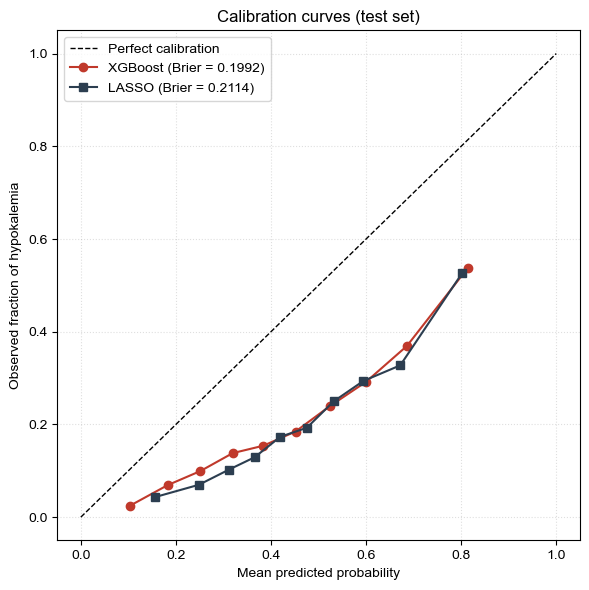

XGBoost Brier = 0.1992
LASSO   Brier = 0.2114


In [8]:
# ========== 单元格 5：校准曲线（修复版）==========
import matplotlib as mpl
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

mpl.rcParams['font.family'] = 'Arial'
mpl.rcParams['font.sans-serif'] = ['Arial']
mpl.rcParams['axes.unicode_minus'] = False

n_bins = 10
frac_pos_xgb, mean_pred_xgb = calibration_curve(
    y_test, y_prob_xgb, n_bins=n_bins, strategy='quantile')
brier_xgb = brier_score_loss(y_test, y_prob_xgb)

frac_pos_lasso, mean_pred_lasso = calibration_curve(
    y_test, y_prob_lasso, n_bins=n_bins, strategy='quantile')
brier_lasso = brier_score_loss(y_test, y_prob_lasso)

with mpl.rc_context({'font.family': 'Arial'}):
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.plot([0, 1], [0, 1], 'k--', linewidth=1, label='Perfect calibration')
    ax.plot(mean_pred_xgb, frac_pos_xgb, 'o-',
            color='#C0392B', linewidth=1.5, markersize=6,
            label=f'XGBoost (Brier = {brier_xgb:.4f})')
    ax.plot(mean_pred_lasso, frac_pos_lasso, 's-',
            color='#2C3E50', linewidth=1.5, markersize=6,
            label=f'LASSO (Brier = {brier_lasso:.4f})')
    ax.set_xlabel('Mean predicted probability', family='Arial')
    ax.set_ylabel('Observed fraction of hypokalemia', family='Arial')
    ax.set_title('Calibration curves (test set)', family='Arial')
    ax.legend(loc='upper left', prop={'family': 'Arial', 'size': 10})
    ax.grid(linestyle=':', alpha=0.4)
    plt.tight_layout()
    plt.savefig('Figure_calibration_curves.png', dpi=300, bbox_inches='tight')
    plt.show()

print(f'XGBoost Brier = {brier_xgb:.4f}')
print(f'LASSO   Brier = {brier_lasso:.4f}')

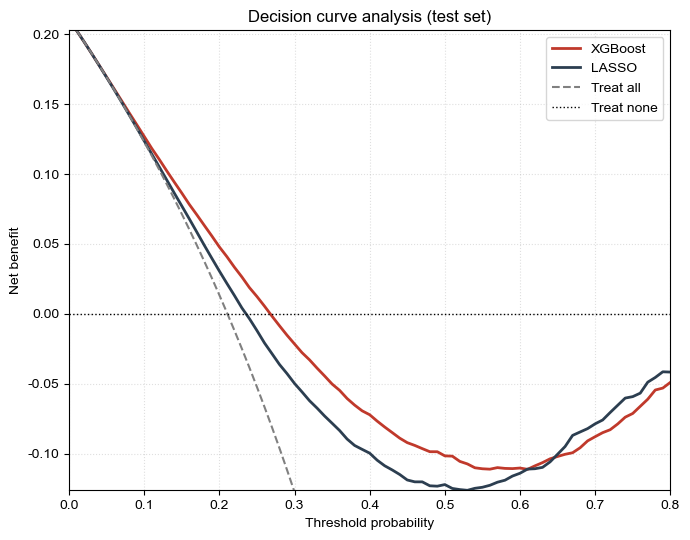

阈值     XGBoost    LASSO    TreatAll
0.10    +0.1270   +0.1238   +0.1231
0.15    +0.0864   +0.0772   +0.0715
0.20    +0.0479   +0.0306   +0.0135
0.25    +0.0124   -0.0119   -0.0523
0.30    -0.0215   -0.0498   -0.1275
0.40    -0.0722   -0.0997   -0.3154


In [9]:
# ========== 单元格 6：DCA ==========
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt

mpl.rcParams['font.family'] = 'Arial'
mpl.rcParams['axes.unicode_minus'] = False

def net_benefit(y_true, y_prob, thresholds):
    y_true = np.asarray(y_true)
    y_prob = np.asarray(y_prob)
    n = len(y_true)
    nb = []
    for pt in thresholds:
        pred = (y_prob >= pt).astype(int)
        tp = ((pred == 1) & (y_true == 1)).sum()
        fp = ((pred == 1) & (y_true == 0)).sum()
        nb.append(tp / n - fp / n * (pt / (1 - pt)))
    return np.array(nb)

thresholds = np.arange(0.01, 0.99, 0.01)
nb_xgb   = net_benefit(y_test, y_prob_xgb,   thresholds)
nb_lasso = net_benefit(y_test, y_prob_lasso, thresholds)
nb_all   = net_benefit(y_test, np.ones_like(y_test, dtype=float), thresholds)

with mpl.rc_context({'font.family': 'Arial'}):
    fig, ax = plt.subplots(figsize=(7, 5.5))
    ax.plot(thresholds, nb_xgb,   color='#C0392B', linewidth=2, label='XGBoost')
    ax.plot(thresholds, nb_lasso, color='#2C3E50', linewidth=2, label='LASSO')
    ax.plot(thresholds, nb_all,   color='gray', linewidth=1.5,
            linestyle='--', label='Treat all')
    ax.axhline(0, color='black', linewidth=1, linestyle=':', label='Treat none')
    ax.set_xlim(0, 0.8)
    y_min = min(nb_xgb.min(), nb_lasso.min(), -0.05)
    y_max = max(nb_xgb.max(), nb_lasso.max(), nb_all.max(), 0.05)
    ax.set_ylim(y_min, y_max)
    ax.set_xlabel('Threshold probability', family='Arial')
    ax.set_ylabel('Net benefit', family='Arial')
    ax.set_title('Decision curve analysis (test set)', family='Arial')
    ax.legend(loc='upper right', prop={'family': 'Arial', 'size': 10})
    ax.grid(linestyle=':', alpha=0.4)
    plt.tight_layout()
    plt.savefig('Figure_DCA.png', dpi=300, bbox_inches='tight')
    plt.show()

print('阈值     XGBoost    LASSO    TreatAll')
for pt in [0.10, 0.15, 0.20, 0.25, 0.30, 0.40]:
    i = np.argmin(np.abs(thresholds - pt))
    print(f'{thresholds[i]:.2f}    {nb_xgb[i]:+.4f}   '
          f'{nb_lasso[i]:+.4f}   {nb_all[i]:+.4f}')

In [10]:
# ========== B：48-72h 限定窗分析 ==========
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

df_win = df_main.copy()
df_win['y_48_72'] = pd.to_numeric(df_win['hypokalemia_48_72h'],
                                   errors='coerce')

print(f'总样本: {len(df_win)}')
print(f'y_48_72 缺失: {df_win["y_48_72"].isna().sum()}')
print(f'y_48_72 事件数: {int(df_win["y_48_72"].sum())} '
      f'({df_win["y_48_72"].mean()*100:.2f}%)')

df_win = df_win.dropna(subset=['y_48_72']).copy()
df_win['y_48_72'] = df_win['y_48_72'].astype(int)

print('\n各组 48-72h 低钾率:')
print(df_win.groupby('senna_exposed')['y_48_72']
      .agg(['sum', 'count', 'mean']))

formula_win = (
    'y_48_72 ~ senna_exposed + gender_male + '
    'C(age_group, Treatment("65-74")) + '
    'baseline_k + drug_count_no_laxatives + '
    'chf + ckd + dm + diuretic + acei_arb + digoxin + '
    'insulin + statin + anticoagulant + '
    'lactulose + peg + bisacodyl + '
    'ppi + beta2_agonist + corticosteroid'
)
model_win = smf.logit(formula_win, data=df_win).fit(disp=0)

or_ = np.exp(model_win.params['senna_exposed'])
lo  = np.exp(model_win.conf_int().loc['senna_exposed', 0])
hi  = np.exp(model_win.conf_int().loc['senna_exposed', 1])
p   = model_win.pvalues['senna_exposed']
print(f'\n48-72h 限定窗结果:')
print(f'  senna aOR = {or_:.3f} ({lo:.3f}–{hi:.3f}), P = {p:.3g}')

总样本: 41529
y_48_72 缺失: 0
y_48_72 事件数: 2143 (5.16%)

各组 48-72h 低钾率:
                sum  count      mean
senna_exposed                       
0               853  17303  0.049298
1              1290  24226  0.053249

48-72h 限定窗结果:
  senna aOR = 1.041 (0.942–1.151), P = 0.427


In [11]:
# ========== C1：Time-dependent Cox 数据准备 ==========
import numpy as np
import pandas as pd

# 若未安装：pip install lifelines
from lifelines import CoxTimeVaryingFitter

df_cox = df_main.copy()

# 时间列
time_cols = ['admittime', 'index_time', 'hypokalemia_time',
             'dischtime', 'deathtime']
for c in time_cols:
    if c in df_cox.columns:
        df_cox[c] = pd.to_datetime(df_cox[c], dayfirst=True, errors='coerce')

def compute_end_time(row):
    candidates = []
    for c in ['hypokalemia_time', 'dischtime', 'deathtime']:
        if pd.notna(row[c]):
            candidates.append(row[c])
    return min(candidates) if candidates else pd.NaT

df_cox['end_time'] = df_cox.apply(compute_end_time, axis=1)
df_cox['event'] = (
    df_cox['hypokalemia_time'].notna() &
    (df_cox['hypokalemia_time'] == df_cox['end_time'])
).astype(int)

# 构造时变数据集
rows = []
for _, r in df_cox.iterrows():
    if pd.isna(r['admittime']) or pd.isna(r['end_time']):
        continue
    t_end = (r['end_time'] - r['admittime']).total_seconds() / 3600
    if t_end <= 0:
        continue
    base = {
        'hadm_id': r['hadm_id'],
        'gender_male': r['gender_male'],
        'age_group': r['age_group'],
        'baseline_k': r['baseline_k'],
        'drug_count_no_laxatives': r['drug_count_no_laxatives'],
        'chf': r['chf'], 'diuretic': r['diuretic'],
    }
    # 暴露组且 index_time 在观察窗内：切两段
    if (r['senna_exposed'] == 1 and pd.notna(r['index_time'])
            and r['admittime'] <= r['index_time'] < r['end_time']):
        t_idx = (r['index_time'] - r['admittime']).total_seconds() / 3600
        if t_idx > 0:
            rows.append({**base, 'start': 0, 'stop': t_idx,
                         'event': 0, 'senna_td': 0})
        rows.append({**base, 'start': t_idx, 'stop': t_end,
                     'event': int(r['event']), 'senna_td': 1})
    else:
        rows.append({**base, 'start': 0, 'stop': t_end,
                     'event': int(r['event']), 'senna_td': 0})

df_td = pd.DataFrame(rows)
print(f'原始患者: {len(df_main)}')
print(f'时变数据集行数: {len(df_td)}')
print(f'  暴露时段数: {(df_td["senna_td"]==1).sum()}')
print(f'  事件数: {df_td["event"].sum()}')

原始患者: 41529
时变数据集行数: 65699
  暴露时段数: 24178
  事件数: 8743


In [12]:
# ========== C2：拟合 Time-dependent Cox ==========
df_td['age_75_84']  = (df_td['age_group'] == '75-84').astype(int)
df_td['age_85plus'] = (df_td['age_group'] == '85+').astype(int)

features_td = ['senna_td', 'gender_male',
               'age_75_84', 'age_85plus',
               'baseline_k', 'drug_count_no_laxatives',
               'chf', 'diuretic']

df_fit = df_td[['hadm_id', 'start', 'stop', 'event'] + features_td].dropna()

ctv = CoxTimeVaryingFitter(penalizer=0.01)
ctv.fit(df_fit, id_col='hadm_id',
        start_col='start', stop_col='stop', event_col='event')

print(ctv.summary)

hr = np.exp(ctv.params_['senna_td'])
lo = np.exp(ctv.confidence_intervals_.loc['senna_td'].iloc[0])
hi = np.exp(ctv.confidence_intervals_.loc['senna_td'].iloc[1])
p  = ctv.summary.loc['senna_td', 'p']
print(f'\nTime-dependent Cox:')
print(f'  senna_td HR = {hr:.3f} ({lo:.3f}–{hi:.3f}), P = {p:.3g}')

                             coef  exp(coef)  se(coef)  coef lower 95%  \
covariate                                                                
senna_td                 0.676183   1.966357  0.022043        0.632980   
gender_male             -0.248744   0.779779  0.020861       -0.289632   
age_75_84                0.032884   1.033431  0.023090       -0.012371   
age_85plus               0.073932   1.076733  0.028115        0.018827   
baseline_k              -0.976279   0.376710  0.025906       -1.027053   
drug_count_no_laxatives  0.023398   1.023674  0.001969        0.019540   
chf                      0.009803   1.009851  0.024262       -0.037749   
diuretic                 0.186817   1.205406  0.023669        0.140425   

                         coef upper 95%  exp(coef) lower 95%  \
covariate                                                      
senna_td                       0.719385             1.883214   
gender_male                   -0.207857             0.748539   
age